# Olist ECデータ分析：出荷遅延と顧客レビューの関係

**目的：** 配送プロセスのどこに改善余地があるかを、顧客レビューと販売者・商品カテゴリーの両面から把握する。

本ノートブックでは、次の2種類の遅延を明確に分けて分析する。

1. **顧客への配送遅延**：実際の顧客配達日時が、注文時の予定配達日時を超えたか。
2. **販売者の出荷引き渡し遅延**：配送業者への引き渡し日時が、商品ごとの出荷期限を超えたか。

この2つは異なる工程・異なる基準の指標であり、同じ「遅延」として混同しない。分析結果は観察データに基づく関連性であり、因果関係を証明するものではない。

> 実行環境：Google Colab / Python  
> データ：Olist Brazilian E-Commerce Public Dataset


## 1. 分析の流れ

- データ読み込み・型変換
- 注文単位のデータを作成し、顧客への配送遅延とレビュー評価を比較
- 注文単位の配送工程日数を分解し、遅延注文の特徴を確認
- 商品単位のデータを注文×販売者×カテゴリー単位に整理
- 販売者別・カテゴリー別・販売者×カテゴリー別に出荷期限超過を比較
- 販売者の出荷期限超過率とレビュー評価の関係を確認
- 分析結果から改善優先候補と施策を考察

**分析単位に注意：** 顧客レビュー分析は「注文単位」、販売者・カテゴリー分析は「注文×販売者」または「注文×販売者×カテゴリー単位」で集計する。複数商品を含む注文をそのまま注文単位の分析に混ぜない。


## 2. ライブラリとデータ読み込み

Google Drive内に `ZOZO_DataAnalysis/data/` フォルダを置いている前提。フォルダ名や保存場所が異なる場合は `DATA_DIR` を変更する。


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

DATA_DIR = "/content/drive/MyDrive/ZOZO_DataAnalysis/data"

required_files = [
    "olist_orders_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_products_dataset.csv",
]

missing_files = [f for f in required_files if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing_files:
    raise FileNotFoundError(
        "次のCSVが見つかりません。DATA_DIRとファイル名を確認してください: "
        + ", ".join(missing_files)
    )

orders = pd.read_csv(os.path.join(DATA_DIR, "olist_orders_dataset.csv"))
reviews = pd.read_csv(os.path.join(DATA_DIR, "olist_order_reviews_dataset.csv"))
order_items = pd.read_csv(os.path.join(DATA_DIR, "olist_order_items_dataset.csv"))
products = pd.read_csv(os.path.join(DATA_DIR, "olist_products_dataset.csv"))

print("orders:", orders.shape)
print("reviews:", reviews.shape)
print("order_items:", order_items.shape)
print("products:", products.shape)


Mounted at /content/drive
orders: (99441, 8)
reviews: (99224, 7)
order_items: (112650, 7)
products: (32951, 9)


## 3. 前処理と分析用データの作成

### 3-1. 日付型への変換
日付文字列を `datetime` 型に変換する。変換できない値は欠損値として扱う。


In [ ]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"], errors="coerce"
)

print("注文ステータス")
display(orders["order_status"].value_counts(dropna=False).to_frame("count"))

print("\n注文データの欠損数")
display(orders[date_columns].isna().sum().to_frame("missing_count"))


注文ステータス


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2



注文データの欠損数


,missing_count
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


### 3-2. レビューを注文単位に集約

同じ注文に複数のレビュー行が存在する場合、レビュー評価の平均をその注文の代表値とする。これにより、注文データとの結合で注文行が不必要に増えることを防ぐ。


In [ ]:
reviews_unique = (
    reviews.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

print("レビュー行数:", len(reviews))
print("注文単位に集約後:", len(reviews_unique))
print("集約後の注文ID重複数:", reviews_unique["order_id"].duplicated().sum())


レビュー行数: 99224
注文単位に集約後: 98673
集約後の注文ID重複数: 0


### 3-3. 注文単位の分析データ

顧客への配送遅延を分析するため、配送完了済みで実際の配達日時と予定配達日時が存在し、レビュー評価も取得できる注文に限定する。


In [ ]:
analysis_df = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].merge(reviews_unique, on="order_id", how="inner")

analysis_df = analysis_df.dropna(subset=["review_score"]).copy()

analysis_df["customer_delay_days"] = (
    analysis_df["order_delivered_customer_date"]
    - analysis_df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

analysis_df["customer_late"] = analysis_df["customer_delay_days"] > 0

print("分析対象注文数:", len(analysis_df))
print("注文ID重複数:", analysis_df["order_id"].duplicated().sum())
print("顧客への配送遅延率: {:.2f}%".format(analysis_df["customer_late"].mean() * 100))
display(analysis_df[["customer_delay_days", "customer_late", "review_score"]].describe())


分析対象注文数: 95824
注文ID重複数: 0
顧客への配送遅延率: 7.99%


,customer_delay_days,review_score
count,95824.000000,95824.000000
mean,-11.215213,4.156158
std,10.114097,1.283615
min,-146.016123,1.000000
25%,-16.248435,4.000000
50%,-11.973050,5.000000
75%,-6.407182,5.000000
max,188.975081,5.000000


## 4. 顧客への配送遅延とレビュー評価

ここでの遅延は、**実際の顧客配達日時 − 予定配達日時** が0日を超えることと定義する。予定日当日までの配達は遅延なしとする。


In [ ]:
customer_delivery_summary = (
    analysis_df.groupby("customer_late")
    .agg(
        order_count=("order_id", "nunique"),
        average_review=("review_score", "mean"),
        median_review=("review_score", "median"),
        low_review_rate=("review_score", lambda x: x.isin([1, 2]).mean() * 100),
        average_delay_days=("customer_delay_days", "mean"),
    )
)
customer_delivery_summary.index = ["予定日以内", "予定日超過"]
display(customer_delivery_summary.round(3))

review_gap = (
    customer_delivery_summary.loc["予定日以内", "average_review"]
    - customer_delivery_summary.loc["予定日超過", "average_review"]
)
print(f"平均レビュー評価の差（予定日以内 − 予定日超過）: {review_gap:.3f}")


,order_count,average_review,median_review,low_review_rate,average_delay_days
予定日以内,88163,4.294,5.0,9.180,-13.011
予定日超過,7661,2.567,2.0,53.975,9.446


平均レビュー評価の差（予定日以内 − 予定日超過）: 1.728


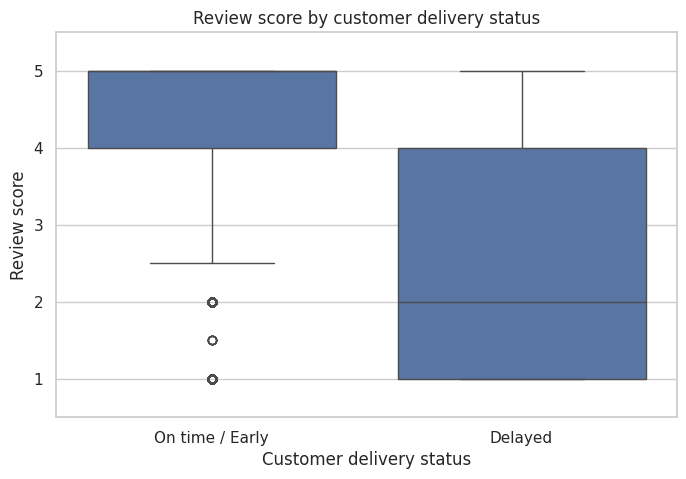

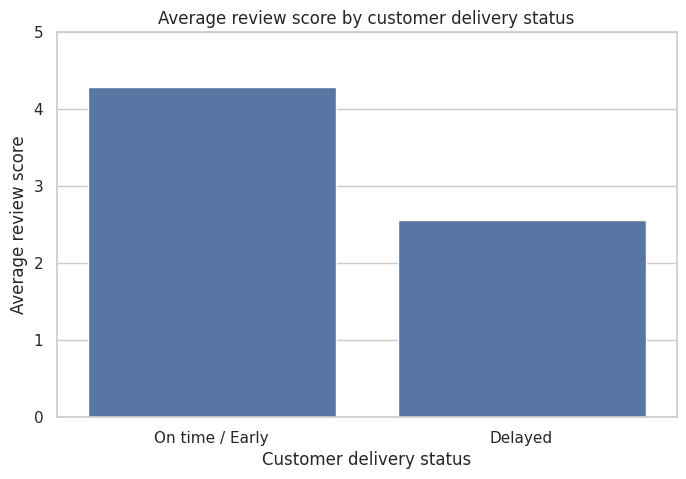

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=analysis_df, x="customer_late", y="review_score")
plt.xticks([0, 1], ["On time / Early", "Delayed"])
plt.xlabel("Customer delivery status")
plt.ylabel("Review score")
plt.title("Review score by customer delivery status")
plt.ylim(0.5, 5.5)
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=analysis_df.assign(delivery_status=analysis_df["customer_late"].map({False: "On time / Early", True: "Delayed"})),
    x="delivery_status", y="review_score", errorbar=None
)
plt.xlabel("Customer delivery status")
plt.ylabel("Average review score")
plt.title("Average review score by customer delivery status")
plt.ylim(0, 5)
plt.show()


### 4-1. 遅延日数と低評価率

レビュー評価1・2を「低評価」と定義する。遅延日数のグループごとに注文数と低評価率を確認する。


,order_count,average_review,low_review_rate
customer_delay_group,,,
予定日以内,88163,4.294,9.180
1〜3日遅延,2636,3.767,19.082
4〜7日遅延,1773,2.317,61.252
8〜14日遅延,1748,1.745,78.032
15日以上遅延,1504,1.711,78.590


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20104 (\N{CJK UNIFIED IDEOGRAPH-4E88}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23450 (\N{CJK UNIFIED IDEOGRAPH-5B9A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20197 (\N{CJK UNIFIED IDEOGRAPH-4EE5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20869 (\N{CJK UNIFIED IDEOGRAPH-5185}) missing from font(s) DejaVu Sans.
  fig.canvas

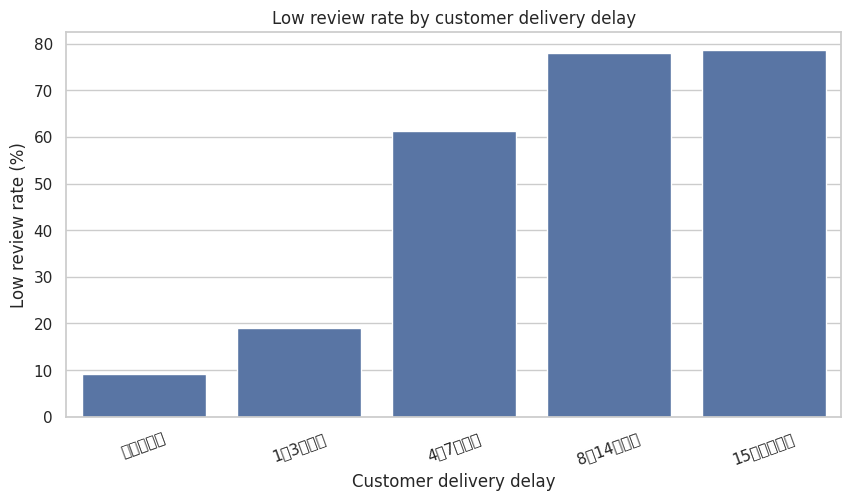

In [ ]:
analysis_df["customer_delay_group"] = pd.cut(
    analysis_df["customer_delay_days"],
    bins=[-np.inf, 0, 3, 7, 14, np.inf],
    labels=["予定日以内", "1〜3日遅延", "4〜7日遅延", "8〜14日遅延", "15日以上遅延"],
    right=True,
)
analysis_df["low_review"] = analysis_df["review_score"].isin([1, 2])

delay_review_summary = (
    analysis_df.groupby("customer_delay_group", observed=False)
    .agg(
        order_count=("order_id", "nunique"),
        average_review=("review_score", "mean"),
        low_review_rate=("low_review", "mean"),
    )
)
delay_review_summary["low_review_rate"] *= 100
display(delay_review_summary.round(3))

plot_delay = delay_review_summary.reset_index().dropna(subset=["customer_delay_group"])
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_delay, x="customer_delay_group", y="low_review_rate", errorbar=None)
plt.xlabel("Customer delivery delay")
plt.ylabel("Low review rate (%)")
plt.title("Low review rate by customer delivery delay")
plt.xticks(rotation=20)
plt.show()


### 4-2. 統計的な差の確認（参考）

2群のレビュー評価分布の差をMann–Whitney U検定で確認する。大きなサンプルでは小さな差でも有意になり得るため、p値だけでなく平均値の差・サンプル数も併せて解釈する。


In [ ]:
on_time_scores = analysis_df.loc[~analysis_df["customer_late"], "review_score"]
late_scores = analysis_df.loc[analysis_df["customer_late"], "review_score"]

u_stat, p_value = stats.mannwhitneyu(
    on_time_scores, late_scores, alternative="two-sided"
)
print("Mann–Whitney U statistic:", round(u_stat, 2))
print("p-value:", f"{p_value:.6g}")
print("注意：統計的有意性は因果関係を意味しない。")


Mann–Whitney U statistic: 524735917.5
p-value: 0
注意：統計的有意性は因果関係を意味しない。


## 5. 配送プロセスの工程別分析

注文日時から配送業者への引き渡しまでを「注文〜引き渡し」、引き渡しから顧客への到着までを「輸送」として分ける。どちらの工程に時間がかかっているか、顧客への配送遅延の有無で比較する。


In [ ]:
delivery_df = analysis_df.copy()

delivery_df["order_to_carrier_days"] = (
    delivery_df["order_delivered_carrier_date"]
    - delivery_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_df["carrier_to_customer_days"] = (
    delivery_df["order_delivered_customer_date"]
    - delivery_df["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

# 負の日数・欠損値は工程日数の比較から除外する
valid_delivery_df = delivery_df[
    delivery_df["order_to_carrier_days"].notna()
    & delivery_df["carrier_to_customer_days"].notna()
    & (delivery_df["order_to_carrier_days"] >= 0)
    & (delivery_df["carrier_to_customer_days"] >= 0)
].copy()

print("注文単位の全対象:", len(delivery_df))
print("2工程の日数が有効な注文:", len(valid_delivery_df))
print("注文〜引き渡しの欠損:", delivery_df["order_to_carrier_days"].isna().sum())
print("引き渡し〜顧客到着の欠損:", delivery_df["carrier_to_customer_days"].isna().sum())

process_summary = (
    valid_delivery_df.groupby("customer_late")
    .agg(
        order_count=("order_id", "nunique"),
        average_order_to_carrier=("order_to_carrier_days", "mean"),
        median_order_to_carrier=("order_to_carrier_days", "median"),
        average_carrier_to_customer=("carrier_to_customer_days", "mean"),
        median_carrier_to_customer=("carrier_to_customer_days", "median"),
        average_review=("review_score", "mean"),
    )
)
process_summary.index = ["予定日以内", "予定日超過"]
display(process_summary.round(3))


注文単位の全対象: 95824
2工程の日数が有効な注文: 95636
注文〜引き渡しの欠損: 1
引き渡し〜顧客到着の欠損: 1


,order_count,average_order_to_carrier,median_order_to_carrier,average_carrier_to_customer,median_carrier_to_customer,average_review
予定日以内,87979,3.001,2.140,7.884,6.923,4.295
予定日超過,7657,5.818,3.443,25.563,23.868,2.566


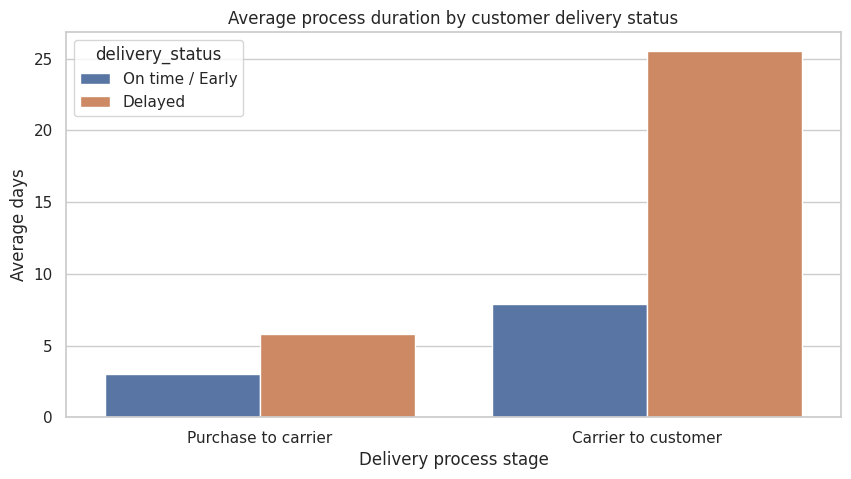

In [ ]:
process_plot = valid_delivery_df.melt(
    id_vars="customer_late",
    value_vars=["order_to_carrier_days", "carrier_to_customer_days"],
    var_name="process_stage",
    value_name="days",
)
process_plot["delivery_status"] = process_plot["customer_late"].map(
    {False: "On time / Early", True: "Delayed"}
)
process_plot["process_stage"] = process_plot["process_stage"].map({
    "order_to_carrier_days": "Purchase to carrier",
    "carrier_to_customer_days": "Carrier to customer",
})
plt.figure(figsize=(10, 5))
sns.barplot(
    data=process_plot, x="process_stage", y="days",
    hue="delivery_status", errorbar=None
)
plt.ylabel("Average days")
plt.xlabel("Delivery process stage")
plt.title("Average process duration by customer delivery status")
plt.show()


## 6. 販売者・カテゴリー分析用データの作成

ここでは、商品明細に注文・商品カテゴリー・注文単位レビューを結合する。出荷期限は商品明細ごとに設定されるため、まず商品明細単位で期限超過を判定する。

その後、販売者の評価では **注文×販売者単位**、販売者×カテゴリーの評価では **注文×販売者×カテゴリー単位** にまとめる。これにより、同じ注文の同じ販売者・カテゴリーに複数商品があっても、レビュー評価が商品数分だけ重複して集計されることを防ぐ。

この分析の「件数」は、注文×販売者（または注文×販売者×カテゴリー）の組み合わせ数であり、注文総数や商品点数とは異なる。


In [ ]:
seller_item = (
    order_items
    .merge(
        orders[[
            "order_id", "order_status", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_purchase_timestamp",
            "order_approved_at"
        ]],
        on="order_id", how="inner"
    )
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id", how="left"
    )
    .merge(reviews_unique, on="order_id", how="inner")
)

seller_item["shipping_delay_days"] = (
    seller_item["order_delivered_carrier_date"]
    - seller_item["shipping_limit_date"]
).dt.total_seconds() / 86400

seller_item["shipping_overdue"] = (
    seller_item["order_delivered_carrier_date"].notna()
    & seller_item["shipping_limit_date"].notna()
    & (seller_item["shipping_delay_days"] > 0)
)

# 引き渡し日時と出荷期限の両方が確認できる商品明細に限定
seller_item_valid = seller_item[
    seller_item["order_status"].eq("delivered")
    & seller_item["shipping_delay_days"].notna()
].copy()

print("商品明細の結合後:", len(seller_item))
print("有効な出荷期限比較対象:", len(seller_item_valid))
print("販売者数:", seller_item_valid["seller_id"].nunique())
print("カテゴリー数:", seller_item_valid["product_category_name"].nunique())


商品明細の結合後: 111708
有効な出荷期限比較対象: 109368
販売者数: 2965
カテゴリー数: 73


### 6-1. 注文×販売者単位に集約

同一注文に同じ販売者の商品が複数ある場合、1つの注文×販売者の組み合わせにまとめる。少なくとも1つの商品明細で出荷期限を超過していれば、その注文×販売者を「期限超過あり」とする。遅延日数は明細の最大値を使用する。


In [ ]:
seller_order = (
    seller_item_valid.groupby(["order_id", "seller_id"], as_index=False)
    .agg(
        shipping_overdue=("shipping_overdue", "max"),
        shipping_delay_days=("shipping_delay_days", "max"),
        review_score=("review_score", "first"),
        order_delivered_carrier_date=("order_delivered_carrier_date", "first"),
        order_approved_at=("order_approved_at", "first"),
    )
)

print("注文×販売者の組み合わせ数:", len(seller_order))
print("組み合わせの重複:", seller_order.duplicated(["order_id", "seller_id"]).sum())


注文×販売者の組み合わせ数: 97157
組み合わせの重複: 0


## 7. 販売者別の出荷期限超過分析

販売者ごとの注文×販売者件数、出荷期限超過率、平均出荷期限超過日数、平均レビュー評価を集計する。件数が少ない販売者は率が大きく変動しやすいため、まず30件以上の販売者を比較対象とする。


In [ ]:
seller_summary = (
    seller_order.groupby("seller_id")
    .agg(
        order_seller_count=("order_id", "count"),
        overdue_count=("shipping_overdue", "sum"),
        overdue_rate=("shipping_overdue", "mean"),
        average_shipping_delay_days=("shipping_delay_days", "mean"),
        average_review=("review_score", "mean"),
    )
    .reset_index()
)

seller_summary["overdue_rate_pct"] = seller_summary["overdue_rate"] * 100
seller_summary["average_shipping_delay_days"] = seller_summary["average_shipping_delay_days"]

seller_summary_30 = seller_summary[
    seller_summary["order_seller_count"] >= 30
].copy()

print("全販売者数:", len(seller_summary))
print("30件以上の販売者数:", len(seller_summary_30))
display(
    seller_summary_30.sort_values("overdue_rate_pct", ascending=False)
    .head(15)
    .round(3)
)


全販売者数: 2965
30件以上の販売者数: 623


,seller_id,order_seller_count,overdue_count,overdue_rate,average_shipping_delay_days,average_review,overdue_rate_pct
839,48efc9d94a9834137efd9ea76b065a38,33,28,0.848,1.427,5.000,84.848
1553,835f0f7810c76831d6c7d24c7a646d4d,42,31,0.738,3.862,3.357,73.810
1958,a7f13822ceb966b076af67121f87b063,72,43,0.597,0.973,3.403,59.722
1924,a49928bcdf77c55c6d6e05e09a9b4ca5,96,53,0.552,1.391,3.031,55.208
341,1da366cade6d8276e7d8beea7af5d4bf,41,22,0.537,0.148,3.976,53.659
998,54965bbe3e4f07ae045b90b0b8541f52,69,37,0.536,8.437,3.145,53.623
323,1ca7077d890b907f89be8c954a02686a,107,55,0.514,-0.295,2.393,51.402
2543,db2956745b3a8e9f3785c99f34b5d25e,45,22,0.489,-0.693,3.844,48.889
1552,834f8533b2ecb6598dd004ff3de7203a,41,20,0.488,1.738,3.951,48.780
2007,ad781527c93d00d89a11eecd9dcad7c1,38,18,0.474,-2.062,3.342,47.368


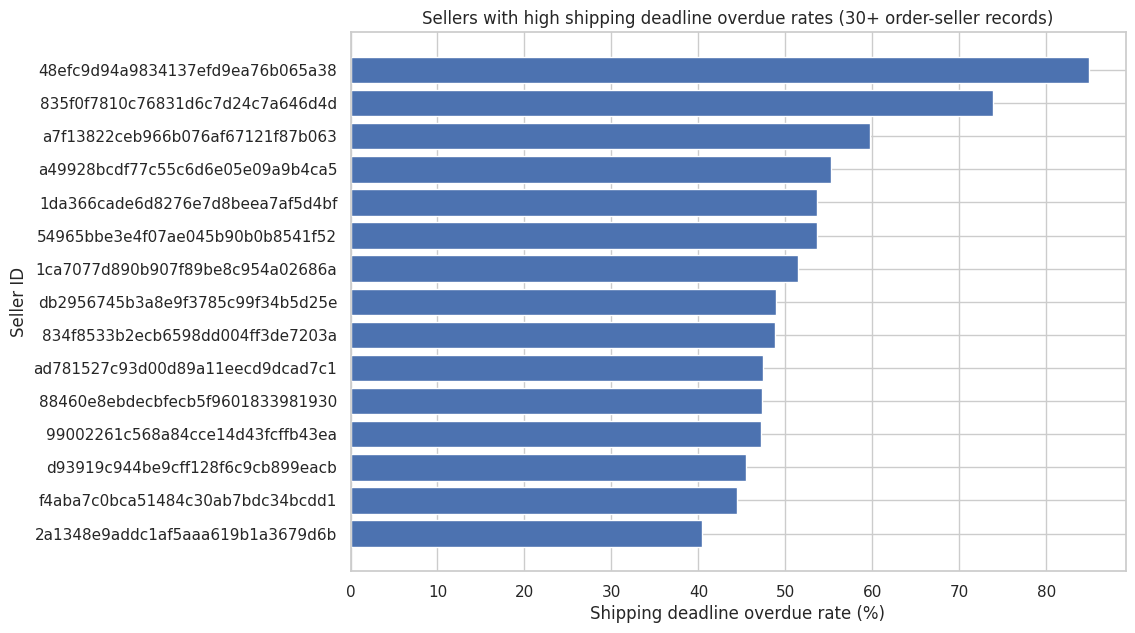

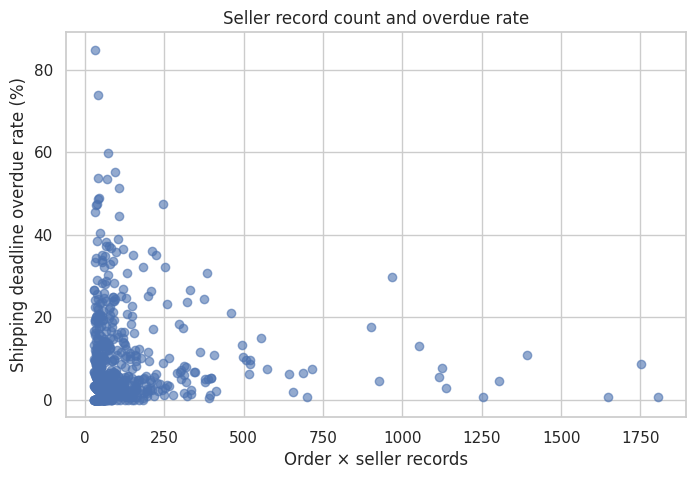

In [ ]:
seller_top = seller_summary_30.sort_values(
    "overdue_rate_pct", ascending=False
).head(15).sort_values("overdue_rate_pct")

plt.figure(figsize=(10, 7))
plt.barh(
    seller_top["seller_id"].astype(str),
    seller_top["overdue_rate_pct"]
)
plt.xlabel("Shipping deadline overdue rate (%)")
plt.ylabel("Seller ID")
plt.title("Sellers with high shipping deadline overdue rates (30+ order-seller records)")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(
    seller_summary_30["order_seller_count"],
    seller_summary_30["overdue_rate_pct"],
    alpha=0.6
)
plt.xlabel("Order × seller records")
plt.ylabel("Shipping deadline overdue rate (%)")
plt.title("Seller record count and overdue rate")
plt.show()


## 8. 商品カテゴリー別の出荷期限超過分析

商品カテゴリーごとに注文×販売者×カテゴリーの組み合わせを集計する。30件以上を比較対象とし、件数と超過率をセットで確認する。


In [ ]:
seller_category = (
    seller_item_valid.groupby(
        ["order_id", "seller_id", "product_category_name"], as_index=False
    )
    .agg(
        shipping_overdue=("shipping_overdue", "max"),
        shipping_delay_days=("shipping_delay_days", "max"),
        review_score=("review_score", "first"),
    )
)

category_summary = (
    seller_category.groupby("product_category_name")
    .agg(
        record_count=("order_id", "count"),
        overdue_count=("shipping_overdue", "sum"),
        overdue_rate=("shipping_overdue", "mean"),
        average_shipping_delay_days=("shipping_delay_days", "mean"),
        average_review=("review_score", "mean"),
    )
    .reset_index()
)

category_summary["overdue_rate_pct"] = category_summary["overdue_rate"] * 100
category_summary_30 = category_summary[
    category_summary["record_count"] >= 30
].copy()

print("全カテゴリー数:", len(category_summary))
print("30件以上のカテゴリー数:", len(category_summary_30))
display(
    category_summary_30.sort_values("overdue_rate_pct", ascending=False)
    .head(15)
    .round(3)
)


全カテゴリー数: 73
30件以上のカテゴリー数: 62


,product_category_name,record_count,overdue_count,overdue_rate,average_shipping_delay_days,average_review,overdue_rate_pct
36,fashion_roupa_feminina,36,10,0.278,-1.366,3.917,27.778
55,moveis_escritorio,1246,341,0.274,-2.243,3.639,27.368
39,fashion_underwear_e_moda_praia,116,25,0.216,-1.847,4.009,21.552
56,moveis_quarto,90,19,0.211,-3.096,4.256,21.111
38,fashion_roupa_masculina,106,22,0.208,-2.470,3.792,20.755
16,casa_construcao,484,92,0.190,-2.644,3.979,19.008
6,artigos_de_natal,124,19,0.153,-3.342,4.089,15.323
3,artes,193,29,0.150,-3.760,4.098,15.026
47,livros_importados,50,7,0.140,-2.855,4.440,14.000
53,moveis_cozinha_area_de_servico_jantar_e_jardim,239,32,0.134,-2.999,4.126,13.389


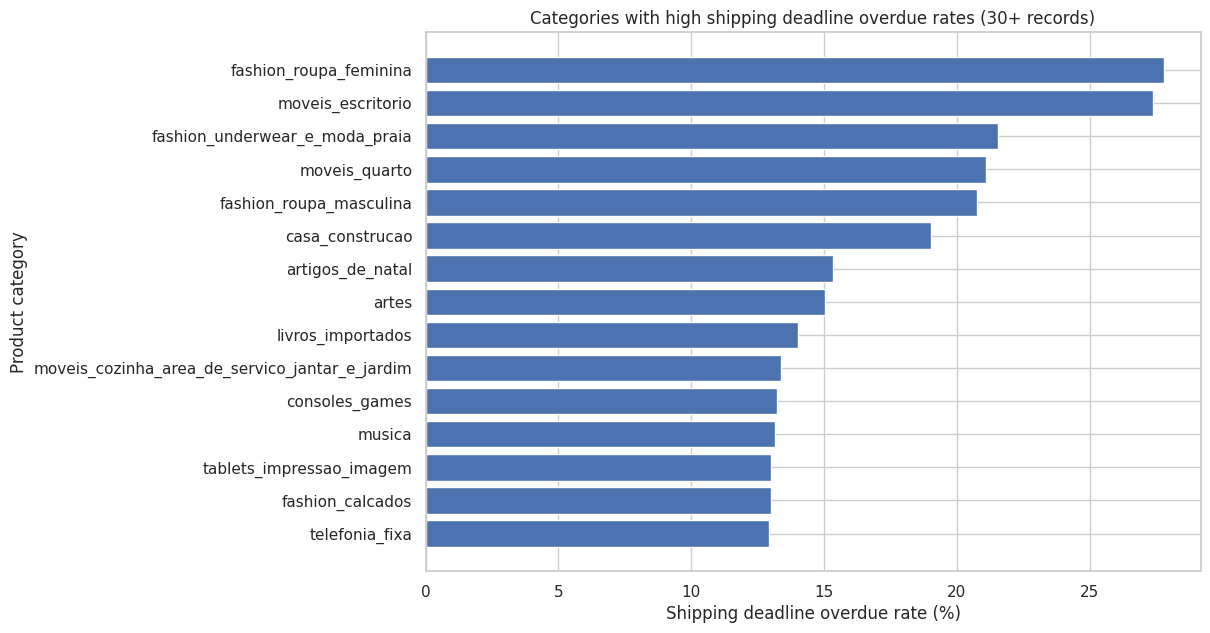

In [ ]:
category_top = category_summary_30.sort_values(
    "overdue_rate_pct", ascending=False
).head(15).sort_values("overdue_rate_pct")

plt.figure(figsize=(10, 7))
plt.barh(
    category_top["product_category_name"].astype(str),
    category_top["overdue_rate_pct"]
)
plt.xlabel("Shipping deadline overdue rate (%)")
plt.ylabel("Product category")
plt.title("Categories with high shipping deadline overdue rates (30+ records)")
plt.show()


## 9. 販売者×カテゴリー別の改善候補

販売者全体の傾向だけでは、特定カテゴリーの商品を扱うときに遅延が増えるケースを見落とす可能性がある。そこで販売者×カテゴリー単位で集計し、30件以上の組み合わせに絞って超過率の高い候補を抽出する。

**注意：** 30件という基準は比較の安定性を高めるための分析上の足切りであり、統計的に十分なサンプル数を保証するものではない。


In [ ]:
seller_category_summary = (
    seller_category.groupby(["product_category_name", "seller_id"])
    .agg(
        record_count=("order_id", "count"),
        overdue_count=("shipping_overdue", "sum"),
        overdue_rate=("shipping_overdue", "mean"),
        average_shipping_delay_days=("shipping_delay_days", "mean"),
        average_review=("review_score", "mean"),
    )
    .reset_index()
)

seller_category_summary["overdue_rate_pct"] = (
    seller_category_summary["overdue_rate"] * 100
)

seller_category_30 = seller_category_summary[
    seller_category_summary["record_count"] >= 30
].copy()

improvement_candidates = seller_category_30.sort_values(
    ["overdue_rate_pct", "record_count"],
    ascending=[False, False]
)

print("販売者×カテゴリーの全組み合わせ数:", len(seller_category_summary))
print("30件以上の組み合わせ数:", len(seller_category_30))
print("改善候補（上位8組）:")
display(
    improvement_candidates[
        ["product_category_name", "seller_id", "record_count",
         "overdue_count", "overdue_rate_pct",
         "average_shipping_delay_days", "average_review"]
    ].head(8).round(3)
)


販売者×カテゴリーの全組み合わせ数: 6130
30件以上の組み合わせ数: 622
改善候補（上位8組）:


,product_category_name,seller_id,record_count,overdue_count,overdue_rate_pct,average_shipping_delay_days,average_review
5914,utilidades_domesticas,835f0f7810c76831d6c7d24c7a646d4d,34,25,73.529,4.199,3.559
4733,moveis_escritorio,a7f13822ceb966b076af67121f87b063,67,41,61.194,1.101,3.448
1507,brinquedos,a49928bcdf77c55c6d6e05e09a9b4ca5,82,47,57.317,1.127,2.976
4406,moveis_decoracao,1da366cade6d8276e7d8beea7af5d4bf,31,17,54.839,0.006,4.097
1670,cama_mesa_banho,54965bbe3e4f07ae045b90b0b8541f52,69,37,53.623,8.437,3.145
2494,cool_stuff,e9bc59e7b60fc3063eb2290deda4cced,45,23,51.111,-0.426,3.800
5419,relogios_presentes,c60b801f2d52c7f7f91de00870882a75,30,15,50.000,0.032,3.367
1280,beleza_saude,db2956745b3a8e9f3785c99f34b5d25e,45,22,48.889,-0.693,3.844


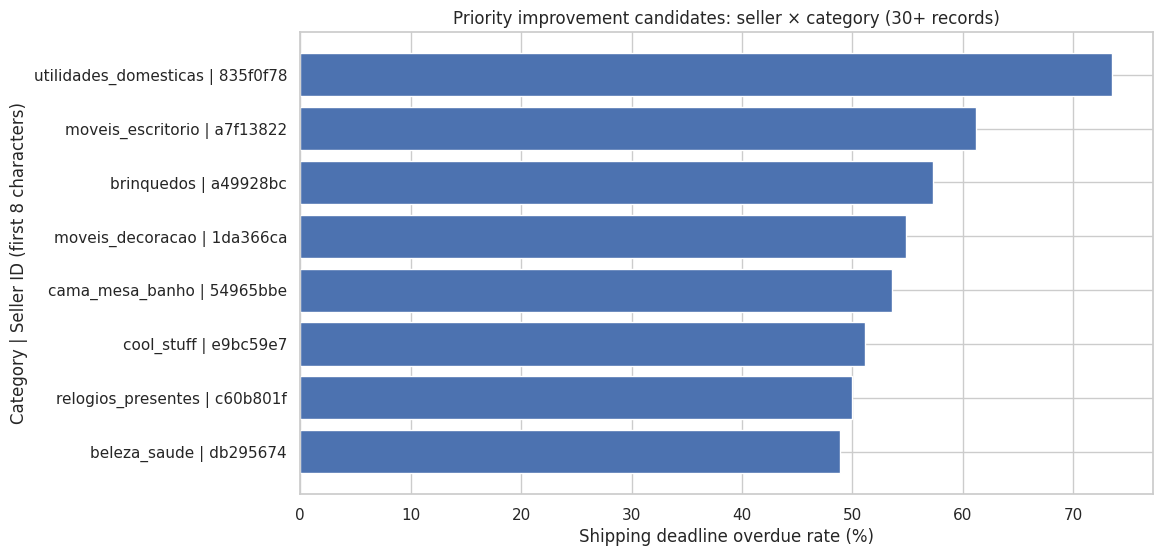

In [ ]:
candidate_plot = improvement_candidates.head(8).copy()
candidate_plot["label"] = (
    candidate_plot["product_category_name"].astype(str)
    + " | " + candidate_plot["seller_id"].astype(str).str.slice(0, 8)
)
candidate_plot = candidate_plot.sort_values("overdue_rate_pct")

plt.figure(figsize=(11, 6))
plt.barh(candidate_plot["label"], candidate_plot["overdue_rate_pct"])
plt.xlabel("Shipping deadline overdue rate (%)")
plt.ylabel("Category | Seller ID (first 8 characters)")
plt.title("Priority improvement candidates: seller × category (30+ records)")
plt.show()


## 10. 販売者の出荷期限超過率とレビュー評価の関係

販売者単位に集約した出荷期限超過率と平均レビュー評価の相関を確認する。Pearson相関は直線的な関係、Spearman相関は順位の単調な関係を捉える。

販売者ごとの平均値を用いるため、個々の注文における因果関係を示すものではない。また、販売者の取扱商品・地域・注文量など、他の要因を調整していない。


対象販売者数: 623
Pearson r: -0.464, p-value: 1.46678e-34
Spearman rho: -0.414, p-value: 3.24659e-27


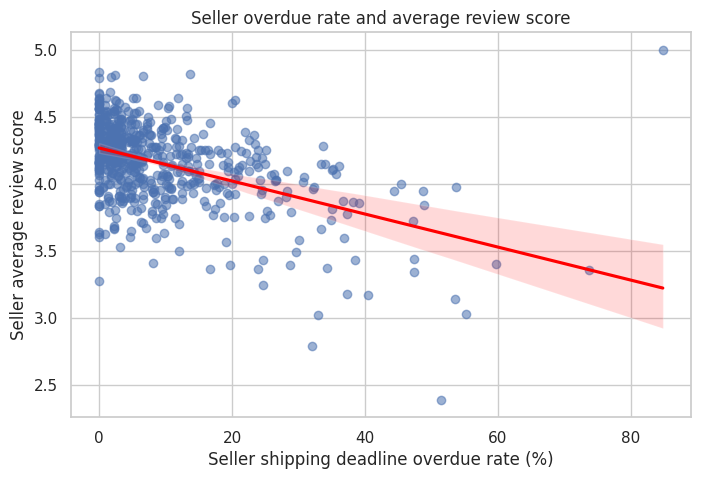

In [ ]:
corr_df = seller_summary_30[
    ["overdue_rate_pct", "average_review", "order_seller_count"]
].dropna()

pearson_r, pearson_p = stats.pearsonr(
    corr_df["overdue_rate_pct"], corr_df["average_review"]
)
spearman_r, spearman_p = stats.spearmanr(
    corr_df["overdue_rate_pct"], corr_df["average_review"]
)

print("対象販売者数:", len(corr_df))
print(f"Pearson r: {pearson_r:.3f}, p-value: {pearson_p:.6g}")
print(f"Spearman rho: {spearman_r:.3f}, p-value: {spearman_p:.6g}")

plt.figure(figsize=(8, 5))
sns.regplot(
    data=corr_df, x="overdue_rate_pct", y="average_review",
    scatter_kws={"alpha": 0.55}, line_kws={"color": "red"}
)
plt.xlabel("Seller shipping deadline overdue rate (%)")
plt.ylabel("Seller average review score")
plt.title("Seller overdue rate and average review score")
plt.show()


## 11. 分析結果の読み取り方・考察

以下の観点で、実行結果を確認して文章を完成させる。

1. **顧客への配送遅延とレビュー：** 予定日超過注文の平均レビュー評価・低評価率が予定日以内の注文と比べてどう異なるか。差の大きさも確認する。
2. **配送工程：** 予定日超過注文では「注文〜引き渡し」と「引き渡し〜顧客到着」のどちらが長いか。工程ごとの平均だけでなく中央値も見る。
3. **販売者：** 30件以上の販売者の中で出荷期限超過率が高い販売者はどこか。注文×販売者件数も併記し、少数データによる極端な率を避ける。
4. **カテゴリー：** 超過率の高いカテゴリーはどこか。特定カテゴリーに共通した商品特性や取り扱い上の難しさがあるかは、追加情報なしに断定しない。
5. **販売者×カテゴリー：** 販売者全体ではなく、特定カテゴリーとの組み合わせに改善余地が集中していないか。
6. **レビューとの関連：** 販売者の出荷期限超過率と平均レビューに負の相関が見られる場合でも、「出荷遅延がレビュー低下を引き起こした」とは断定しない。

### 改善施策の仮説
- 出荷期限超過率が高い販売者には、注文受付から出荷準備・引き渡しまでの作業時間を工程別に確認する。
- 特定カテゴリーで超過が目立つ場合は、在庫配置、梱包作業、商品サイズ・取り扱い条件などを追加調査する。
- 注文〜引き渡しに時間がかかる場合は、販売者側の出荷準備・集荷連携を優先して確認する。
- 引き渡し後の輸送時間が長い場合は、配送地域・配送業者・配送ルートなどを追加分析する。

これらは分析結果から導く**検証すべき仮説**であり、現時点で原因と確定したものではない。


## 12. 分析上の限界

- Olistの公開データは過去の特定期間・特定市場のデータであり、現在のEC市場全体を代表するとは限らない。
- 顧客レビューには配送以外の商品品質・価格・問い合わせ対応なども影響する。
- 販売者・カテゴリー別の分析では、出荷期限が確認できる配送完了商品明細を対象としている。データ欠損や未配送注文は対象外となる。
- 出荷期限超過と顧客への配送遅延は別指標であり、販売者の引き渡しが遅れても予定日より早く届く場合、またその逆もあり得る。
- 相関分析は他の要因を調整しておらず、因果関係を示さない。
- 30件以上という基準は便宜的な基準である。候補を実務で採用する際は、より多いサンプル数・期間別の安定性・信頼区間なども確認する必要がある。


## 13. まとめ

この分析では、顧客への配送遅延とレビュー評価の関係を注文単位で確認したうえで、販売者の出荷期限超過を注文×販売者・カテゴリー単位で比較した。

最終的な改善優先順位は、**超過率だけでなく対象件数、平均遅延日数、レビュー評価、工程別所要日数を組み合わせて**判断する。特定の販売者・カテゴリーを改善候補として挙げる場合は、集計表に示された件数と率を必ず併記する。
